In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
sys.path.append(os.path.abspath('../../espaloma-charge_mod/'))
sys.path.append(os.path.abspath('../'))
import ResParTools as pt
from espaloma_charge import charge
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True

# Расчёт зарядов модифицированного остатка - версия без словарей

Тот же протокол, что в `1_charge_calculation.ipynb`, но все данные хранятся **в самой молекуле RDKit**
(схема - `docs/MOL_PROPS.md`):

| Свойство | у чего | шаг | что значит |
|---|---|---|---|
| `ModName`, `SourceFile` | молекула | 1 | имя и файл исходной молекулы |
| `SrcIdx` | атом | 1 | индекс атома в исходном файле |
| `PolymerIdx` | атом | 2 | индекс атома в тримере |
| `PrevIdx`, `ParentName` | атом | 3 | индекс до перенумерации; имя атома в родительском остатке (у новых атомов свойства нет) |
| `Parent`, `RefResidue`, `Naming` | молекула | 3 | родитель, его шаблон, способ имён |
| `AtomName` | атом | 3-4 | имя атома в остатке |
| `AddedH` | атом | 4.1 | водород, добавленный только для acpype |
| `Charge<Метод>`, `ChargeFixed` | атом | 5-6 | заряды каждого метода (`ChargeEspaloma`, `ChargeRESP`, ...), фиксированные атомы остова |
| `ChargeMethod` | молекула | 5-6 | метод, чьи заряды пойдут в силовое поле |

Между шагами молекула сохраняется одним файлом: `pt.save_mol` / `pt.load_mol` (SDF со всеми свойствами).
Функции, которые раньше возвращали словари (`file_opener`, `match_mon_to_pol`), здесь заменены на
`pt.open_mol` и `pt.find_residue` - они возвращают одну молекулу.

In [2]:
# Параметры модификации
PTM_name = 'Lysine_Formyl'
base_name = 'KFO'
parent_residue = 'K'
monomer_file = 'molecules/K_form.smiles'
trimer_file = 'molecules/AK_formA.smiles'
naming = 'greek'
resp_run = 'local'
run_resp_now = False          # True - запустить RESP в этом ноутбуке (долго: около часа на лизин)
# куда писать результаты (вне git; окончательное место - обсуждается)
OUT = os.path.join('..', 'build', 'props', os.path.basename(os.getcwd()))
os.makedirs(OUT, exist_ok=True)

## Шаг 1. Мономер и тример
`pt.open_mol` - одна молекула; у атомов `SrcIdx`, у молекулы `ModName`, `SourceFile`.

In [3]:
monomer = pt.open_mol(monomer_file)
trimer = pt.open_mol(trimer_file)
mon_name = monomer.GetProp('ModName')
print(mon_name, monomer.GetNumAtoms(), '|', trimer.GetProp('ModName'), trimer.GetNumAtoms())

Загрузка файла: K_form (формат: .smiles)
Загрузка файла: AK_formA (формат: .smiles)
K_form 25 | AK_formA 45


## Шаг 2. Остаток внутри тримера
`pt.find_residue` возвращает остаток (атомы мономера); у каждого атома - `PolymerIdx`, его индекс в тримере.

Выполнение Поиск подструктуры между молекулами.  


Поиск подструктуры между молекулами выполнен успешно!


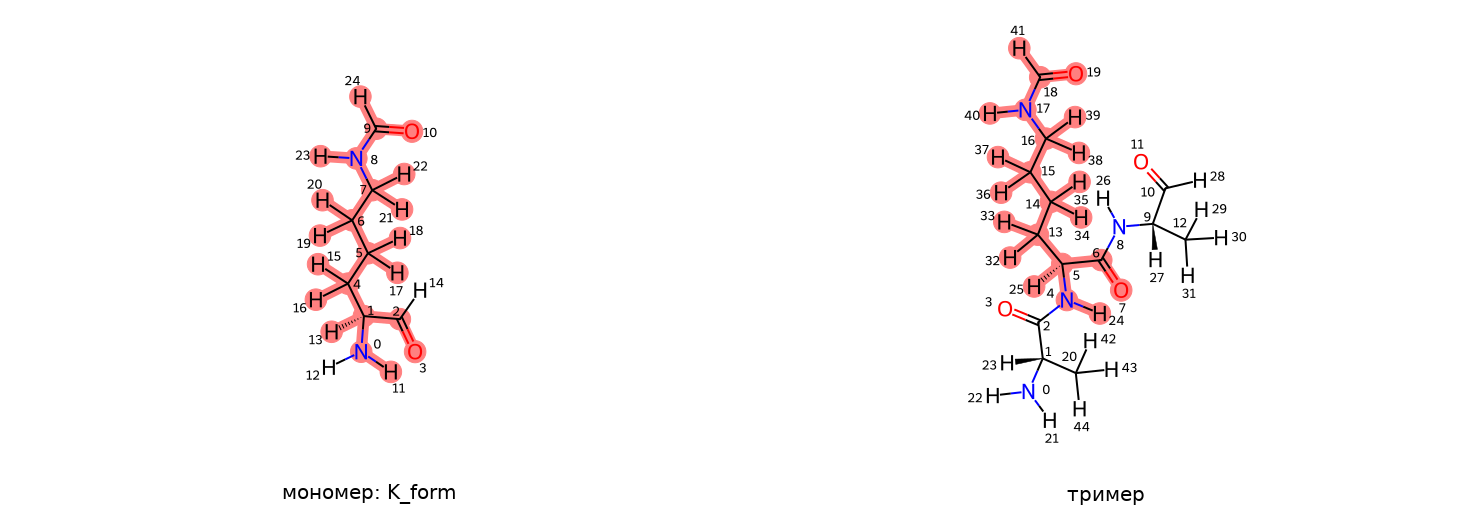

In [4]:
residue = pt.find_residue(monomer, trimer, timeout=5)
in_trimer = [a.GetIntProp('PolymerIdx') for a in residue.GetAtoms()]
in_monomer = [a.GetIntProp('SrcIdx') for a in residue.GetAtoms()]
pt.draw_mol_grid([monomer, trimer], legends=[f'мономер: {mon_name}', 'тример'],
                 highlight_atoms=[in_monomer, in_trimer])

## Шаг 3. Перенумерация и имена атомов
Атомы родительского остатка получают `ParentName`; список `parent_atoms` больше не хранится - он вычисляется из свойств.

Выполнение Поиск подструктуры между молекулами.  


Поиск подструктуры между молекулами выполнен успешно!
Родительский остаток: лизин (Lys, K), шаблон GKG_H; сопоставлено атомов: 18.
⚠ Не сопоставлены атомы боковой цепи ['NZ'] (1 из 4): вероятно, это место модификации.
Перенумеровано атомов: 21 из 23 (канонических: 18)
Имена атомов (буквенный способ): N H CA HA CB HB1 HB2 CG HG1 HG2 CD HD1 HD2 CE HE1 HE2 NZ HZ CH HH OT C O


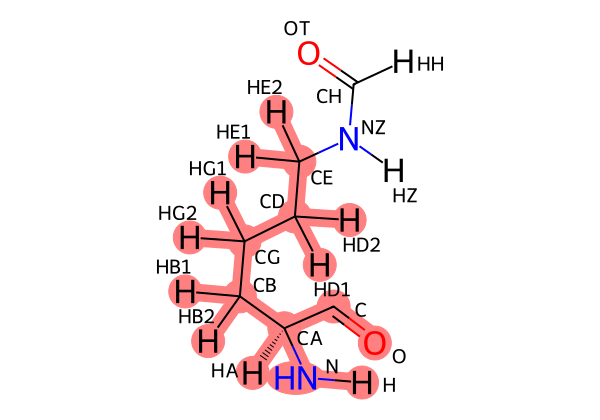

In [5]:
residue = pt.renumber_residue_atoms(residue, ref_base_name=parent_residue, timeout=5)
parent_atoms = [a.GetIdx() for a in residue.GetAtoms() if a.HasProp('ParentName')]
residue = pt.rdkit_pdb_modification(residue, resname=base_name, resid=2, segid='A',
                                    naming=naming, parent_atoms=parent_atoms)
pt.draw_molecule(residue, highlight_atoms=parent_atoms, show_names=True, show_index=False)

## Шаг 4. Правка имён, проверка дубликатов
`rename_map = {'старое имя': 'новое имя'}`; пустой - имена не меняются.

In [6]:
rename_map = {}
residue = pt.modifie_residue_info(residue, rename_map, resname=base_name, resid=2, segid='A')
duplicates = pt.check_duplicate_atom_names(residue)
if duplicates:
    raise ValueError(f'Повторяющиеся имена атомов (имя: индексы): {duplicates}')

Дубликаты имен атомов не найдены.


In [7]:
# таблица атомов: всё, что известно об атоме, - в его свойствах
for a in residue.GetAtoms():
    print(f"{a.GetIdx():3d} {a.GetProp('AtomName'):5s} родитель: {a.GetProp('ParentName') if a.HasProp('ParentName') else '-':5s} "
          f"исходный индекс: {a.GetIntProp('SrcIdx'):3d} в тримере: {a.GetIntProp('PolymerIdx'):3d}")

  0 N     родитель: N     исходный индекс:   0 в тримере:   4
  1 H     родитель: H     исходный индекс:  11 в тримере:  24
  2 CA    родитель: CA    исходный индекс:   1 в тримере:   5
  3 HA    родитель: HA    исходный индекс:  13 в тримере:  25
  4 CB    родитель: CB    исходный индекс:   4 в тримере:  13
  5 HB1   родитель: HB1   исходный индекс:  15 в тримере:  32
  6 HB2   родитель: HB2   исходный индекс:  16 в тримере:  33
  7 CG    родитель: CG    исходный индекс:   5 в тримере:  14
  8 HG1   родитель: HG1   исходный индекс:  17 в тримере:  34
  9 HG2   родитель: HG2   исходный индекс:  18 в тримере:  35
 10 CD    родитель: CD    исходный индекс:   6 в тримере:  15
 11 HD1   родитель: HD1   исходный индекс:  19 в тримере:  36
 12 HD2   родитель: HD2   исходный индекс:  20 в тримере:  37
 13 CE    родитель: CE    исходный индекс:   7 в тримере:  16
 14 HE1   родитель: HE1   исходный индекс:  21 в тримере:  38
 15 HE2   родитель: HE2   исходный индекс:  22 в тримере:  39
 16 NZ  

### Шаг 4.1. Водороды для acpype
Добавленные водороды помечены свойством атома `AddedH` (на шаге 3 силового поля удаляются по нему, а не по имени).

Добавлены водороды (имя - атом): HW1 - N (0), HW2 - C (21)


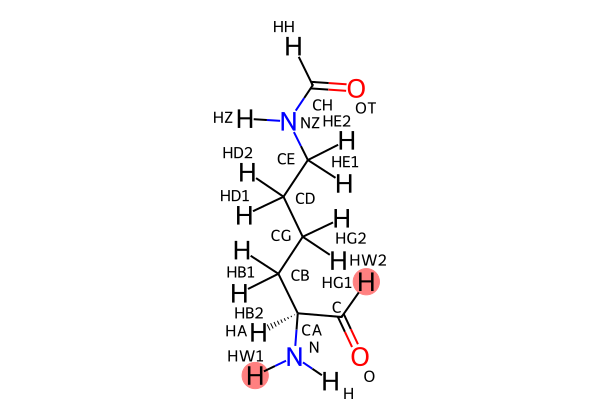

In [8]:
h_residue = pt.add_protons_and_renumber_H(residue, resname=base_name, resid=2, segid='A')
added = [a.GetIdx() for a in h_residue.GetAtoms() if a.HasProp('AddedH') and a.GetBoolProp('AddedH')]
pt.draw_molecule(h_residue, highlight_atoms=added, show_names=True, show_index=False)

## Шаг 5. Заряды Espaloma
Заряды записываются в атомы: `ChargeEspaloma`; фиксированные атомы остова - `ChargeFixed`.

Заряды из LYS (имя, индекс, заряд): N 0 -0.3479, H 1 +0.2747, CA 2 -0.2400, HA 3 +0.1426, C 21 +0.7341, O 22 -0.5894


сумма зарядов: 0.00000 (заряд остатка 0)


/home/nikolay/anaconda3/envs/darwin_ec/lib/python3.12/site-packages/dgl/heterograph.py:92: DGLWarning: Recommend creating graphs by `dgl.graph(data)` instead of `dgl.DGLGraph(data)`.
  dgl_warning(


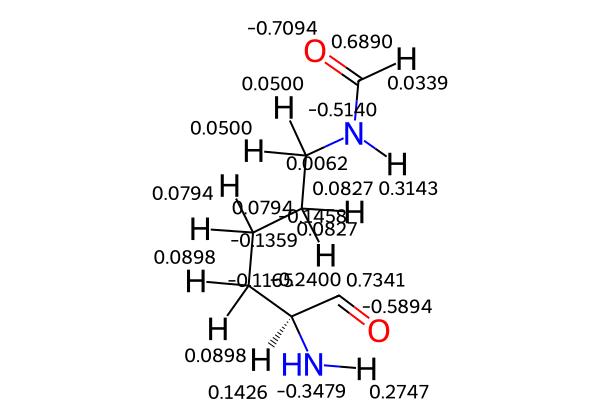

In [9]:
constraints = pt.charge_constraints_from_rtp(residue, pt.AMINO_ACIDS[parent_residue][0].upper())
q = charge(residue, constraints=constraints)
pt.set_charges(residue, q, 'Espaloma', constraints)
total = Chem.GetFormalCharge(residue)
print(f'сумма зарядов: {q.sum():.5f} (заряд остатка {total})')
if abs(q.sum() - total) > 1e-3:
    raise ValueError('Сумма зарядов не равна заряду остатка.')
pt.draw_molecule(residue, charge_list=q, show_names=False, show_index=False)

## Шаг 6. RESP (по желанию)
Задача готовится в `OUT/resp`; считать - `run_resp_now = True` или на кластере. Готовые заряды - в `ChargeRESP`.

In [10]:
resp_folder = pt.prepare_resp_job(residue, constraints, f'{mon_name}_capped', working_dir=os.path.join(OUT, 'resp'),
                                  fix_backbone=True, n_sidechain=3, monomer=monomer)
if run_resp_now:
    pt.run_resp(resp_folder, run=resp_run, n_threads=4, n_parallel=1)
# готовый результат: этой задачи или ночного расчёта (build/resp/<папка>/)
done = [f for f in (resp_folder, os.path.join('..', 'build', 'resp', os.path.basename(os.getcwd()), f'{mon_name}_capped'))
        if os.path.exists(os.path.join(f, 'result.json'))]
if done:
    pt.set_charges(residue, pt.load_resp_result(done[0]), 'RESP', constraints)
    pt.compare_charges(residue, {m: [a.GetDoubleProp(f'Charge{m}') for a in residue.GetAtoms()]
                                 for m in ('Espaloma', 'RESP')})
residue.SetProp('ChargeMethod', 'Espaloma')   # заряды для силового поля

3D-структура, стереоцентры: CA (1) - L (S по CIP)


Конформации RESP (00:01:37): alphaR_1 (phi -60.0, psi -40.0, dE 3.81); alphaR_2 (phi -60.0, psi -40.0, dE 11.56); alphaR_3 (phi -60.0, psi -40.0, dE 8.55); beta_1 (phi -120.0, psi 130.0, dE 2.46); beta_2 (phi -120.0, psi 130.0, dE 10.09); beta_3 (phi -120.0, psi 130.0, dE 7.46)
Стереохимия конформаций проверена: центров 1 (R/S), двойных связей 0 (E/Z) - как задано, CA - L
Задача RESP: /home/nikolay/Documents/VS_code/ResParTools/notebooks_and_examples/build/props/Lysine_Formyl/resp/K_form_capped | молекула 35 атомов (заряд +0, capped), остаток 23 атомов (заряд +0), фиксировано зарядов 18, групп эквивалентных атомов 4, конформаций 6


## Сохранение
Один файл SDF со всеми свойствами (`pt.load_mol` читает его обратно) и 3D PDB для acpype.

In [11]:
path = pt.save_mol(residue, os.path.join(OUT, f'4_{mon_name}'))
pt.save_mol(h_residue, os.path.join(OUT, f'4_1_{mon_name}'))
pt.save_chem_to_pdb(h_residue, os.path.join(OUT, f'{PTM_name}_rn_H_3D'), coords='3D')
back = pt.load_mol(path)
print('свойства молекулы:', back.GetPropsAsDict())
print('свойства атома 0:', back.GetAtomWithIdx(0).GetPropsAsDict())

3D-структура, стереоцентры: CA (2) - L (S по CIP)
свойства молекулы: {'ModName': 'K_form', 'SourceFile': 'molecules/K_form.smiles', 'Parent': 'K', 'RefResidue': 'GKG_H', 'OldIndices': '[0, 11, 1, 12, 4, 13, 14, 5, 15, 16, 6, 17, 18, 7, 19, 20, 8, 21, 9, 22, 10, 2, 3]', 'ParentAtoms': '[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 21, 22]', 'Naming': 'greek', 'ChargeMethod': 'Espaloma', 'ResName': 'KFO', 'ResId': 2, 'Chain': 'A'}
свойства атома 0: {'AtomName': 'N', 'ChargeEspaloma': -0.34790000319480896, 'ChargeFixed': True, 'ParentName': 'N', 'PolymerIdx': 4, 'PrevIdx': 0, 'SrcIdx': 0}
